# Week 6: Experiments and Statistics

In this practical you will conduct experiments to tune the parameters of an EA, learn how to present the results and conduct some statistical testing to determine whether an operator has a signficant effect on the results.

In this tutorial you will learn:

1. How to design and conduct experiments to collect data to investigate the influence of parameters
2. How to calculate statistics from the data
3. How to plot the data using boxplots
4. How to conduct statistical testing using an appropriate test

It is also important that you are able to intepret the boxplots and statistical tests, and explain the observations  using your knowledge of EAs

We will use the EASimple to solve the One-Max problem as a test bed (as it is quick to run) to do multiple experiments and gather some statistics that will help us understand the influence of the various operators and tuning parameters

The code for plotting and calculating statistics can easily be re-used with any EA (e.g. can be useful for your coursework!)

## Libraries for plotting and calculating statistics

Before you start, you will need to make sure you have the  **pandas** library and the **scipy** installed in your system (if you are using Google colabs then this should be there already

In [1]:
# Run this only  if you need to install pandas/scipy
!pip install pandas
!pip install scipy

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

## Set up

Let's first define the EA - this code should all look familiar by now

In [2]:
#  Full code listing for EASimple to solve a OneMax problem

import random


from deap import base
from deap import creator
from deap import tools
from deap import algorithms

import pandas as pd
import scipy
import numpy as np
import matplotlib.pyplot as plt

creator.create("FitnessMax", base.Fitness, weights=(1.0,))
creator.create("Individual", list, fitness=creator.FitnessMax)


toolbox = base.Toolbox()

# random boolean values
toolbox.register("attr_bool", random.randint, 0, 1)

# one max - chromosomes length 100
toolbox.register("individual", tools.initRepeat, creator.Individual, 
    toolbox.attr_bool, 100)

# define the population to be a list of individuals
toolbox.register("population", tools.initRepeat, list, toolbox.individual)


# the goal ('fitness') function to be maximized
def evalOneMax(individual):
    return sum(individual),

# initialse some default start parameters
MUTPB = 0.1
CXPB = 0.6
POPSIZE = 50
NGEN=200
TNSIZE=2


# register the goal / fitness function
toolbox.register("evaluate", evalOneMax)

# register the crossover operator
toolbox.register("mate", tools.cxOnePoint)

# register a mutation operator 
toolbox.register("mutate", tools.mutFlipBit, indpb=MUTPB)

# register crossove
toolbox.register("select", tools.selTournament, tournsize=TNSIZE)




In [3]:
# define a main as usual
def runEA():
    
    # create a new population
    pop = toolbox.population(n=POPSIZE)
    
    # keep track of the single best solution found
    hof = tools.HallOfFame(1)
 
    # create a statistics object: we can log what ever statistics we want using this. We use the numpy Python library
    # to calculate the stats and label them with convenient labels
    stats = tools.Statistics(lambda ind: ind.fitness.values)
    stats.register("avg", np.mean)
    stats.register("std", np.std)
    stats.register("min", np.min)
    stats.register("max", np.max)
    
    # run the algorithm: 
    # cxpb = crossover probability; mutpb = mutation probability; ngen = number of iterations
    pop, log = algorithms.eaSimple(pop, toolbox, cxpb=CXPB, mutpb=MUTPB, ngen=NGEN, 
                                   stats=stats, halloffame=hof, verbose=False)
    
    return pop, log, hof



## How to use this code to collect statistics

Now we have written the EA, we can write some code to call it multiple times. In this example experiment, we create an experiment to investigate the influence of **population size**.  The EA is run for the POPSIZE parameter in a range from 50 to 151 in steps of 50 (i.e. tests 3 values 50,100,150).  For each value of POPSIZE, the EA is run 10 times so we can collate statistics.  

After each run of the algorithm, we can extract the statistics of interest from the logbook and then write them to a dataframe that is going to keep a record of the information of interest from each logbook.  Dataframes are convenient to work with in Python, particularly for collating statistics as we can group the data in any way that's convenient.

**In the first experiment we will investigate whether changing population size has an influence on performance**.

We will run the algorithm with POPSIZE set to values of 50-150 in steps of 50 (it's more interesting to try a wider range of values but takes longer to run of course, so for the purpose of illustration we will just look at a small range of values).  For each value of POPSIZE, we will run the algorithm 10 times.

- After each experiment (i.e. a single run of the EA for a given POPSIZE), we will extract the best fitness found and store in a dataframe. This is a convenient way to manage the data to extract statistics later
- we will also save the log file produced from each experiment as we can use this information to do some plotting later

Run the following - note it still may take some time to run on your machine

In [4]:
# Experiment:  test POPSIZE from 50-150 in steps of 50

all_logs=[]     # make an empty list to store the log files prodiced
rows=[]         # one record per run, turned into a dataframe after the loops (df.append no longer exists in recent pandas)

for  POPSIZE in range(50, 151, 50):  # from 50 to 150 in steps of 50
        # repeat EA 10x for each parameter
        for reps in range(10):
            pop,log,hof = runEA()
            # extract the best fitness
            best = hof[0].fitness.values[0]
            # save the generation this fitness was first found
            maxes = log.select('max')
            for gen in range(NGEN+1):   # the log has NGEN+1 entries (gen 0 to NGEN)
                if maxes[gen] == best:
                    break

            # record the data from this run
            rows.append({'popsize': POPSIZE , 'fitness': best, 'genMaxFound': gen})

            # add the log which has the information about each generation  from each experiment to a list
            all_logs.append(log)

# create the dataframe with 3 columns to record the important data from each run
df_Bests = pd.DataFrame(rows).astype({'popsize': 'int', 'fitness': 'float', 'genMaxFound': 'int'})

# Data
Have a look at the dataframe we have just created - you should see 3 columns showing the best fitness and the generation at which it was found for each run of the algorithm


You can find information about using *pandas* dataframes for plotting and calculating statistics on many data science sites/StackOverflow/Google.... feel free to explore... some useful things are explained in the rest of the notebook

In [5]:
df_Bests

,popsize,fitness,genMaxFound
0,50,92.0,179
1,50,91.0,164
2,50,91.0,74
3,50,93.0,89
4,50,91.0,115
5,50,87.0,111
6,50,92.0,81
7,50,95.0,158
8,50,95.0,182
9,50,93.0,177


# Plotting aggregated data to show the evolutionary trajectory

As in the experiments we did in previous weeks, the logbooks contain the minimum, average and maximum values of fitness function at each generation of the algorithm.

We can aggregate this data over the 10 runs for a particular parameter.  The list *all_logs* contains 30 logs: 10 logs for each of the experiments associated with population size (50, 100, 150):

For example
- all_logs[0] is the log for the 1st run of popsize 50
- all_logs[1] is the log for the 1st run of popsize 50
- ....
- all_logs[10]  is the log for the 1st run of popsize 100
- all_logs[20]  is the log for the 1st run of popsize 100

etc.

For each value of POPSIZE, we can aggregate the log data over the 10 runs: e.g at generation 1 in each run, we can look up the **best fitness value (maximum)**.  This gives us 10 values from each of 10 runs at each generation.  We can calculate the average, minimum and maximum of these 10 values at each generation and plot this data


The code below explains how to extract the aggregated data. We can then plot the convergence curve that shows:

- the mean of the 10 values representing "max" fitness at each generation
- the "maximum" of the 10 values representing "max" fitness at each generation
- the "minumum" of the 10 values representing "max" fitness at each generation

This is a useful graph as it tells us something about how much the different runs vary: if the shaded band is very wide, it means the runs are very variable

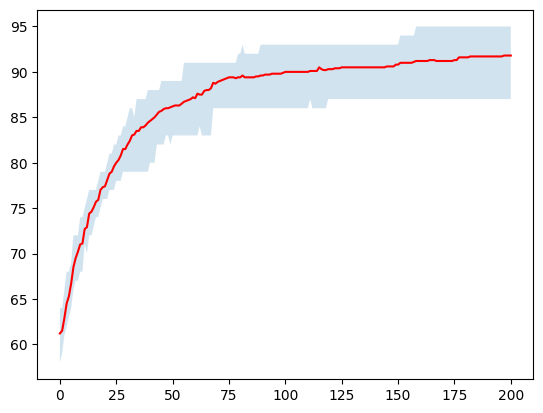

In [6]:


all_logs_df = []


# this loops over logs 0-9, i.e. the 10 logs associate with POPSIZE=50. You can change it for other POPSIZE values
for j in  range(0,10):
    logbook = all_logs[j]  # extract the relacant logbook 
    data = [[i for i in item.values()] for item in logbook]  # this creates a list [0,1,2...n] where n is the length of the log book - it is need for creating the x-axis when plotting
    header = list(logbook.header)
    df = pd.DataFrame(data, columns=header)  # turn the logbook into a dataframe as its easier to work with
    all_logs_df.append(df) # add the log a list of dataframes
       
       
df_result = pd.concat(all_logs_df)   # this makes one dataframe from the 10 separate ones we created above

#calculate the mean value of the 10 best results ("max") found at every generation in every run [i,e from 10 values]
#repeat to calculate the "minimum" value of the 10 best results at each generation
#repeat to calculate the "maximum" value of the 10 best results at each generation

max_mean=df_result['max'].groupby(df_result['gen']).apply(np.mean) # look at the max column, group results by "gen", and apply the relevant statistic
max_max=df_result['max'].groupby(df_result['gen']).apply(np.max)
max_min=df_result['max'].groupby(df_result['gen']).apply(np.min)


#plot convergence curves for data of choice

x = [i for i in range(0,201)]  # make sure this is set to NGEN+1 ... it creates a list [0,1,2,....NGEN] used to define the x-axis for plotting
fig, ax = plt.subplots()
# plot the mean value of the best result per generation
ax.plot(max_mean, color='red')
# not plot the max and min value of the best result per generation and shade to show the variance per run
ax.fill_between(x,max_min, max_max, alpha=0.2)





If you want to view the curves for POPSIZE=100 or POPSIZE=150 then you need to alter the indices in the loop at line 8 in the cell above (e.g. for 10,20 for POPSIZE 100 and 20,30 for POPSIZE 200)

Plot these curves too

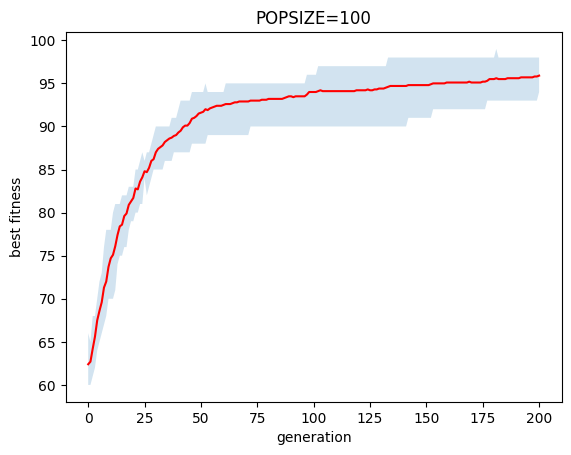

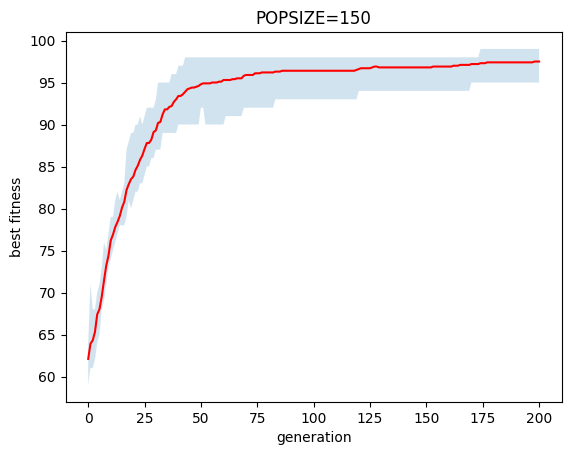

In [7]:
# convergence curves for POPSIZE=100 (logs 10-19) and POPSIZE=150 (logs 20-29)
def plot_convergence(start, label):
    dfs = []
    for logbook in all_logs[start:start+10]:
        data = [[i for i in item.values()] for item in logbook]
        dfs.append(pd.DataFrame(data, columns=list(logbook.header)))
    res = pd.concat(dfs)
    grp = res['max'].groupby(res['gen'])
    x = [i for i in range(0, NGEN+1)]
    fig, ax = plt.subplots()
    ax.plot(grp.mean(), color='red')                     # mean of the best fitness per generation
    ax.fill_between(x, grp.min(), grp.max(), alpha=0.2)  # min/max band over the 10 runs
    ax.set_title(label)
    ax.set_xlabel('generation')
    ax.set_ylabel('best fitness')
    plt.show()

plot_convergence(10, 'POPSIZE=100')
plot_convergence(20, 'POPSIZE=150')

## plotting std and mean

Instead of plotting the mean and using shading to show the max/min variation in values, we can plot the standard deviation at each point


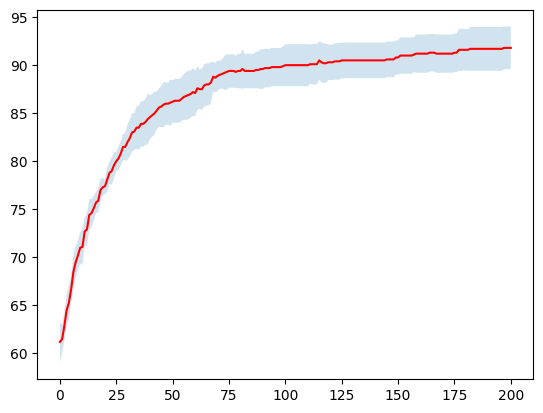

In [8]:

# show std instead of min/max variation
max_std=df_result['max'].groupby(df_result['gen']).apply(np.std)    # calculate standard dev of the values from each of the runs at each generation of the runs

max_max = max_mean+max_std
max_min = max_mean-max_std

x = [i for i in range(0,201)]  # make sure this is set to NGEN+1 ... it creates a list [0,1,2,....NGEN] used to define the x-axis for plotting
fig, ax = plt.subplots()
# plot the mean value of the best result per generation
ax.plot(max_mean, color='red')
# not plot the max and min value of the best result per generation and shade to show the variance per run
ax.fill_between(x,max_min, max_max, alpha=0.2)



# Plotting boxplots

Refer to the lecture for an explanation of a boxplot

Here we aggregate the data by the population size variable and plot the boxplot for each of the 3 values of popsize

Observe whether there is much overlap between the boxes and whether they suggest that one of the values for popsize might produce significantly better results than another 

Look at the second plot which shows the distribution of the value obtained w.r.t the generation at which the best value is found: 
- is there much variation?
- is there a trend (i.e. does increasing popsize result in a decrease at which the best solution is found?

         fitness  genMaxFound
popsize                      
50          92.0        133.0
100         96.1        159.1
150         97.5        134.4


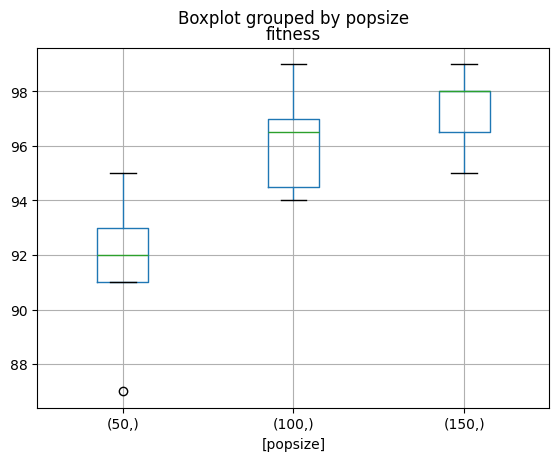

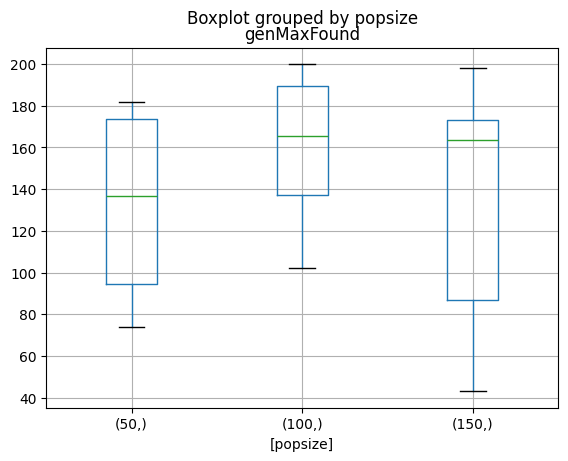

In [9]:
# code for calcualating and printing statistics from the dataframe df_Bests which  (from above) contains that best result per run per popsize
print(df_Bests.groupby('popsize').mean())

#  you can calculate other statistics such as median, std if you want
#print(df_Bests.groupby('popsize').median())
#print(df_Bests.groupby('popsize').std())

# plot the boxplot of best fitness per population size
boxplot = df_Bests.boxplot(column=['fitness'], by=['popsize'])

# plot genMaxFound per population size
boxplot = df_Bests.boxplot(column=['genMaxFound'], by=['popsize'])



##  Statistics

If we want to apply statistical tests, we need to extract the relevant data as lists - see the code below. Refer to the lecture for interpreting the statistical value. Based on the value - can we reject the null hpyothesis "**changing the population size from 50 to 150 has no effect on performance**"

In [10]:
from scipy.stats import mannwhitneyu
from scipy.stats import ttest_ind
from scipy.stats import shapiro

# select two subsets of fitness data, one where popsize = 50 and the other where popsize = 150
p50 = df_Bests.fitness[df_Bests.popsize == 50]
p150= df_Bests.fitness[df_Bests.popsize == 150]

# we need to convert these subsets to lists to pass to the statistics functions
p50l= p50.tolist()
p150l = p150.tolist()

# check for normality
stat,p = shapiro(p50l)
print('p=50: normality p=%f' %(p))

if p<0.05:
    print("Reject null hypothesis (distribution is not normal)")
else:
    print("Cannot reject null hypothesis (assume distribution is normal)")
    
stat,p = shapiro(p150l)
print('p=150: normality p=%f' %(p))
if p<0.05:
    print("Reject null hypothesis (distribution is not normal)")
else:
    print("Cannot reject null hypothesis (assume distribution is normal)")


p=50: normality p=0.230278
Cannot reject null hypothesis (assume distribution is normal)
p=150: normality p=0.037796
Reject null hypothesis (distribution is not normal)


In [11]:
#now apply the  appropriate statistical test depending on the result of the above
# p=50 failed the normality check (p<0.05), so we use the non-parametric Mann-Whitney U test instead of the t-test
#stat,p = ttest_ind(p50l,p150l)
stat,p = mannwhitneyu(p50l,p150l)

print('p=%f' %(p))
if p<0.05:
    print("Reject null hypothesis - there is a significant difference in the experiments")
else:
    print("Cannot reject null hypothesis - no significant difference")

p=0.000206
Reject null hypothesis - there is a significant difference in the experiments


# Task 1: Exploring the effect of mutation rate

Fix all parameters except the mutation rate to values of your own choosing. Now run experiments over a range of mutation values from 0 to 1 in steps 0.2.  Create a boxplot to visualise the results and make sure you can explain what you observe.  

Select the mutation rate that appears to perform best, and the one that appears to perform worst. Conduct a signficance test to determine whether there is a statistically signifcant difference between the two mutation rates. Remember to first test for normality and then apply the appropriate test 

# Task 2: Exploring crossover types:

Now modify the code above to run the EA 10x using 1pt crossover, 2pt crossover and uniform crossover keeping all over parameters fixed.  (Set the crossover, run 10x and write the result to a dataframe that has a column noting the crossover type as well as one to record fitness. Now reset the crossover to the next one to be tested, repeat and add the results to the same dataframe).

Again plot the boxplot and then perform a statistical test between each pair of crossover operators to determine significance


# Task 3: Exploring effect of tournament size

Conduct and experiment to determine the influence of tournament size using a fixed population size of 100. Design the experiment, run it, plot the graphs and conduct a statistical test to determine whether it is possible to reject the null hypothesis "the tournament size has no effect on fitness when solving max-one"


# Task 4: Explore the effect of selection operator:

Design and conduct an experiment to evaluate the hypothesis "there is no difference between tournament selection size 2 and using roulette wheel (fitness proportionate selection).  You can test the latter using the inbuilt DEAP selection operator selRoulette()

---
# Solutions

The cells below solve Tasks 1 to 4. Each task starts from the same default parameters (MUTPB=0.1, CXPB=0.6, POPSIZE=50, NGEN=200, tournament size 2, one point crossover) and changes only the parameter under test.

In [12]:
from itertools import combinations
from scipy.stats import kruskal, f_oneway

# default parameters used as the fixed baseline for every task
def reset_defaults():
    global MUTPB, CXPB, POPSIZE, NGEN, TNSIZE
    MUTPB, CXPB, POPSIZE, NGEN, TNSIZE = 0.1, 0.6, 50, 200, 2
    toolbox.register("mate", tools.cxOnePoint)
    toolbox.register("mutate", tools.mutFlipBit, indpb=MUTPB)
    toolbox.register("select", tools.selTournament, tournsize=TNSIZE)

# is a sample normally distributed? (Shapiro-Wilk, same 0.05 threshold as above)
def is_normal(data):
    if np.ptp(data) == 0:        # all values identical, so the test is meaningless: treat as not normal
        return False, 0.0
    stat, p = shapiro(data)
    return p >= 0.05, p

# compare two samples: check normality first, then pick t-test or Mann-Whitney U
def compare(a, b, name_a, name_b, alpha=0.05):
    na, pa = is_normal(a)
    nb_, pb = is_normal(b)
    print('%s: normality p=%.4f | %s: normality p=%.4f' % (name_a, pa, name_b, pb))
    if np.ptp(a) == 0 and np.ptp(b) == 0 and a[0] == b[0]:
        print('Both samples are identical, no difference')
        return 1.0
    if na and nb_:
        stat, p = ttest_ind(a, b)
        test = 't-test'
    else:
        stat, p = mannwhitneyu(a, b, alternative='two-sided')
        test = 'Mann-Whitney U'
    verdict = 'REJECT null (significant difference)' if p < alpha else 'cannot reject null (no significant difference)'
    print('%s vs %s -> %s, p=%.6f, %s' % (name_a, name_b, test, p, verdict))
    return p

## Task 1: effect of mutation rate

Mutation rate runs from 0 to 1 in steps of 0.2. As in the original setup, the same value is used for the probability that an individual is mutated (mutpb) and for the per-bit flip probability (indpb). All other parameters stay at the defaults. The EA is run 10 times per value.

          mean  median       std
mutation                        
0.0       77.4    78.0  3.098387
0.2       90.0    90.0  1.632993
0.4       79.6    79.5  2.503331
0.6       69.1    69.0  1.728840
0.8       66.7    66.5  1.337494
1.0       62.2    62.0  1.549193


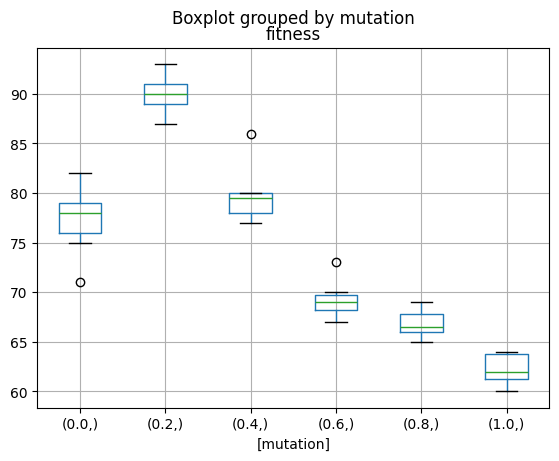

In [13]:
reset_defaults()
rows = []
for mut in [0, 0.2, 0.4, 0.6, 0.8, 1.0]:
    MUTPB = mut
    toolbox.register("mutate", tools.mutFlipBit, indpb=MUTPB)   # re-register so indpb follows MUTPB
    for rep in range(10):
        pop, log, hof = runEA()
        rows.append({'mutation': mut, 'fitness': hof[0].fitness.values[0]})
df_mut = pd.DataFrame(rows)
reset_defaults()

print(df_mut.groupby('mutation')['fitness'].agg(['mean', 'median', 'std']))
df_mut.boxplot(column=['fitness'], by=['mutation'])
plt.show()

In [14]:
# best and worst mutation rate by mean fitness, then test the difference between them
means = df_mut.groupby('mutation')['fitness'].mean()
best_mut, worst_mut = means.idxmax(), means.idxmin()
print('best mutation rate: %s (mean %.1f) | worst: %s (mean %.1f)' % (best_mut, means.max(), worst_mut, means.min()))

a = df_mut.fitness[df_mut.mutation == best_mut].tolist()
b = df_mut.fitness[df_mut.mutation == worst_mut].tolist()
_ = compare(a, b, 'mut=%s' % best_mut, 'mut=%s' % worst_mut)

best mutation rate: 0.2 (mean 90.0) | worst: 1.0 (mean 62.2)
mut=0.2: normality p=0.6665 | mut=1.0: normality p=0.1559
mut=0.2 vs mut=1.0 -> t-test, p=0.000000, REJECT null (significant difference)


**Interpretation (Task 1).** Both extremes do badly and a small to moderate rate does best.
- At 0 there is no mutation, so the EA can only recombine the bits already in the initial population. Bits that are missing at a position in every individual can never come back, so the search stalls below 100.
- At a rate that is too high (0.6 to 1.0) mutation flips a large share of the bits every generation. Good solutions are destroyed faster than selection rebuilds them and the search behaves like a random walk, so fitness stays between about 60 and 70.
- A moderate rate (around 0.2 here) supplies new bits and keeps most of the good structure, so it gives the best fitness.

## Task 2: crossover types

One point, two point and uniform crossover, 10 runs each, all other parameters fixed. Results go into one dataframe with a column for the crossover type.

           mean  median       std
crossover                        
1pt        93.0    93.5  2.449490
2pt        94.1    94.0  1.449138
uniform    97.6    98.0  1.264911


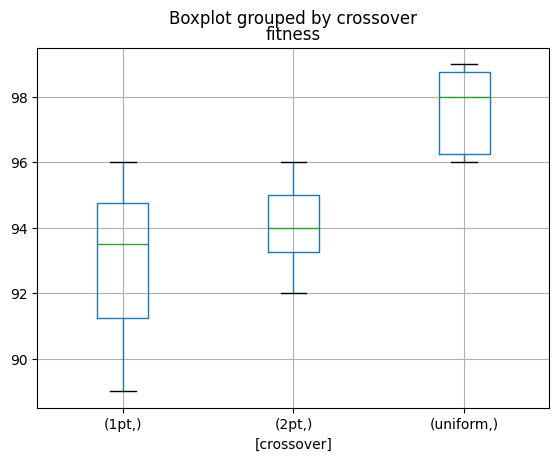

In [15]:
reset_defaults()
crossovers = {
    '1pt':     (tools.cxOnePoint, {}),
    '2pt':     (tools.cxTwoPoint, {}),
    'uniform': (tools.cxUniform, {'indpb': 0.5}),
}
rows = []
for name, (func, kwargs) in crossovers.items():
    toolbox.register("mate", func, **kwargs)
    for rep in range(10):
        pop, log, hof = runEA()
        rows.append({'crossover': name, 'fitness': hof[0].fitness.values[0]})
df_cx = pd.DataFrame(rows)
reset_defaults()

print(df_cx.groupby('crossover')['fitness'].agg(['mean', 'median', 'std']))
df_cx.boxplot(column=['fitness'], by=['crossover'])
plt.show()

In [16]:
# pairwise tests (3 comparisons, so also show the Bonferroni threshold 0.05/3)
print('Bonferroni threshold: %.4f' % (0.05 / 3))
for n1, n2 in combinations(crossovers.keys(), 2):
    a = df_cx.fitness[df_cx.crossover == n1].tolist()
    b = df_cx.fitness[df_cx.crossover == n2].tolist()
    compare(a, b, n1, n2)
    print()

Bonferroni threshold: 0.0167
1pt: normality p=0.5776 | 2pt: normality p=0.3296
1pt vs 2pt -> t-test, p=0.237388, cannot reject null (no significant difference)

1pt: normality p=0.5776 | uniform: normality p=0.0418
1pt vs uniform -> Mann-Whitney U, p=0.000379, REJECT null (significant difference)

2pt: normality p=0.3296 | uniform: normality p=0.0418
2pt vs uniform -> Mann-Whitney U, p=0.000370, REJECT null (significant difference)



**Interpretation (Task 2).** Uniform crossover gives the highest fitness. One point and two point crossover are close to each other.
- OneMax has no linked blocks of bits: every bit adds 1 to the fitness independently of its neighbours. Uniform crossover mixes bits freely, so it combines good bits from both parents and builds better offspring.
- One point and two point crossover keep long runs of bits together, so they recombine less and are slower to assemble the best bits. Two point is only a small step from one point, which matches the overlap in the boxplot and the weak or missing significance between them.
- Read the pairwise p-values against the Bonferroni threshold, because three tests raise the chance of a false positive.

## Task 3: tournament size

POPSIZE is fixed at 100 and the tournament size runs over 2, 3, 5, 7 and 10 (10 runs each).
H0: the tournament size has no effect on fitness when solving OneMax.

           mean  median       std
tournsize                        
2          96.2    96.0  1.135292
3          94.0    94.5  2.624669
5          93.1    94.0  2.330951
7          93.1    92.5  2.078995
10         92.1    92.0  1.852926


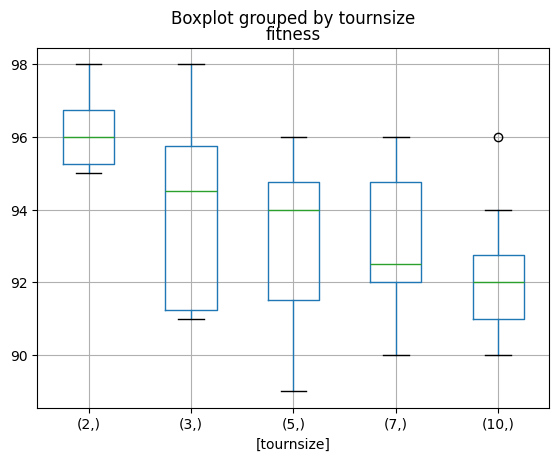

In [17]:
reset_defaults()
POPSIZE = 100
rows = []
for ts in [2, 3, 5, 7, 10]:
    toolbox.register("select", tools.selTournament, tournsize=ts)
    for rep in range(10):
        pop, log, hof = runEA()
        rows.append({'tournsize': ts, 'fitness': hof[0].fitness.values[0]})
df_ts = pd.DataFrame(rows)
reset_defaults()

print(df_ts.groupby('tournsize')['fitness'].agg(['mean', 'median', 'std']))
df_ts.boxplot(column=['fitness'], by=['tournsize'])
plt.show()

In [18]:
# omnibus test over all 5 groups: ANOVA if every group is normal, otherwise Kruskal-Wallis
groups = [df_ts.fitness[df_ts.tournsize == ts].tolist() for ts in [2, 3, 5, 7, 10]]
all_normal = all(is_normal(g)[0] for g in groups)
for ts, g in zip([2, 3, 5, 7, 10], groups):
    print('tournsize=%d: normality p=%.4f' % (ts, is_normal(g)[1]))

if all_normal:
    stat, p = f_oneway(*groups)
    test = 'one-way ANOVA'
else:
    stat, p = kruskal(*groups)
    test = 'Kruskal-Wallis'
print('%s: p=%.6f' % (test, p))
if p < 0.05:
    print('Reject null hypothesis - tournament size has a significant effect on fitness')
else:
    print('Cannot reject null hypothesis - no significant effect of tournament size')

# post-hoc pairwise tests against the Bonferroni threshold (10 pairs)
print()
print('Pairwise tests, Bonferroni threshold: %.4f' % (0.05 / 10))
for t1, t2 in combinations([2, 3, 5, 7, 10], 2):
    a = df_ts.fitness[df_ts.tournsize == t1].tolist()
    b = df_ts.fitness[df_ts.tournsize == t2].tolist()
    na, _ = is_normal(a); nb_, _ = is_normal(b)
    pp = ttest_ind(a, b)[1] if (na and nb_) else mannwhitneyu(a, b, alternative='two-sided')[1]
    print('size %2d vs %2d: p=%.4f %s' % (t1, t2, pp, '*' if pp < 0.05 / 10 else ''))

tournsize=2: normality p=0.0553
tournsize=3: normality p=0.2192
tournsize=5: normality p=0.2299
tournsize=7: normality p=0.4513
tournsize=10: normality p=0.2977
one-way ANOVA: p=0.000924
Reject null hypothesis - tournament size has a significant effect on fitness

Pairwise tests, Bonferroni threshold: 0.0050
size  2 vs  3: p=0.0256 
size  2 vs  5: p=0.0014 *
size  2 vs  7: p=0.0006 *
size  2 vs 10: p=0.0000 *
size  3 vs  5: p=0.4281 
size  3 vs  7: p=0.4065 
size  3 vs 10: p=0.0778 
size  5 vs  7: p=1.0000 
size  5 vs 10: p=0.3023 
size  7 vs 10: p=0.2711 


**Interpretation (Task 3).** Tournament size sets the selection pressure.
- A small tournament (2) gives each individual a fair chance of being picked, so diversity stays high for longer and the EA keeps improving through all 200 generations.
- A large tournament (7, 10) picks almost only the best individuals. The population converges quickly onto copies of a few good individuals, diversity drops and the search stalls at a lower fitness.
- If the omnibus p-value is below 0.05 the null hypothesis is rejected. The pairwise table shows which sizes differ after the Bonferroni correction.

## Task 4: tournament selection (size 2) vs roulette wheel

H0: there is no difference between tournament selection with size 2 and roulette wheel selection (selRoulette). Population size 50, 30 runs per operator for more statistical power, all other parameters at the defaults.

                    mean  median      std
selection                                
roulette       75.500000    75.0  2.27050
tournament(2)  92.566667    92.5  1.50134


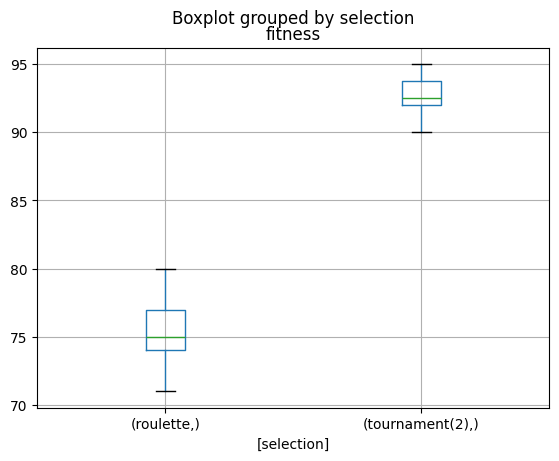

tournament(2): normality p=0.0711 | roulette: normality p=0.5284
tournament(2) vs roulette -> t-test, p=0.000000, REJECT null (significant difference)


In [19]:
reset_defaults()
selectors = {
    'tournament(2)': (tools.selTournament, {'tournsize': 2}),
    'roulette':      (tools.selRoulette, {}),
}
rows = []
for name, (func, kwargs) in selectors.items():
    toolbox.register("select", func, **kwargs)
    for rep in range(30):
        pop, log, hof = runEA()
        rows.append({'selection': name, 'fitness': hof[0].fitness.values[0]})
df_sel = pd.DataFrame(rows)
reset_defaults()

print(df_sel.groupby('selection')['fitness'].agg(['mean', 'median', 'std']))
df_sel.boxplot(column=['fitness'], by=['selection'])
plt.show()

a = df_sel.fitness[df_sel.selection == 'tournament(2)'].tolist()
b = df_sel.fitness[df_sel.selection == 'roulette'].tolist()
_ = compare(a, b, 'tournament(2)', 'roulette')

**Interpretation (Task 4).** Roulette wheel selection performs much worse and the null hypothesis is rejected.
- OneMax fitness values lie roughly between 50 and 100, so the best individual is only a little more likely to be picked than an average one. Roulette selection therefore applies very weak selection pressure and the population improves slowly.
- Tournament selection depends on the ranking of individuals, not on the size of their fitness values, so the pressure stays strong even when the values are close together.

# Finally
Please use any extra time to make sure you have completed the tutorials from previous weeks